# 03 Unsupervised: Node2Vec Experiment Walkthrough

This notebook is the thesis-facing reading entry point for `03_unsupervised`. It follows the experimental sequence and presents the code, tables, and figures from the frozen reconstructed-graph results.

**Method positioning:** Node2Vec is a shallow graph representation learning method. It generates biased random walks over a graph and applies Word2Vec to learn a fixed vector for each address. This unsupervised experiment examines whether topology-derived representations align with publicly available address-role labels.

## 0. File responsibilities and execution scope

- `node2vec/node2vec_clustering.py`: main experiment covering graph construction, 64-dimensional embeddings, t-SNE, KMeans, Louvain, permutation tests, the k scan, and DBSCAN.
- `node2vec/repeated_balanced_ari.py`: 50 repeated balanced samples of 51/51/51 addresses for assessing the influence of class imbalance on ARI.
- `node2vec/node2vec_pq_sensitivity.py`: comparison of baseline, BFS-like, and DFS-like random-walk settings.
- `node2vec/node2vec_pq_multiseed.py`: p/q comparison across five Node2Vec training seeds.
- `node2vec/node2vec_reproducibility.py`: shared random-seed control, stable hashing, and run metadata.
- `node2vec_outputs/node2vec_reconstructed/`: frozen outputs produced by these scripts.

This walkthrough reads the existing outputs for fast and stable execution. Full reproduction follows the Python scripts in the order listed above.

In [1]:
from pathlib import Path

import networkx as nx
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
if cwd.name == "03_unsupervised":
    PROJECT_ROOT = cwd.parent
    UNSUPERVISED_ROOT = cwd
elif (cwd / "03_unsupervised").exists():
    PROJECT_ROOT = cwd
    UNSUPERVISED_ROOT = cwd / "03_unsupervised"
else:
    raise FileNotFoundError("Run this notebook from the project root or the 03_unsupervised directory.")

EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
FEATURE_FILE = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering" / "seed_feature_matrix_reconstructed.csv"
OUTPUT_DIR = UNSUPERVISED_ROOT / "node2vec_outputs" / "node2vec_reconstructed"

required = [EDGES_FILE, FEATURE_FILE, OUTPUT_DIR]
assert all(path.exists() for path in required), [str(path) for path in required if not path.exists()]
display(pd.DataFrame({"role": ["graph input", "labelled feature input", "Node2Vec outputs"],
                      "path": [str(path.relative_to(PROJECT_ROOT)) for path in required]}))

,role,path
0,graph input,00_data_graph\data\main\raw_edges_reconstructe...
1,labelled feature input,02_feature_engineering\feature_engineering\see...
2,Node2Vec outputs,03_unsupervised\node2vec_outputs\node2vec_reco...


## 1. Construct the Node2Vec graph from transaction edges

Each row of `raw_edges_reconstructed.csv` represents an aggregated transaction edge from `source` to `target`; `tx_count` records the number of transactions in that direction. The main script first constructs a directed graph, converts it to an undirected graph, and stores `tx_count` as the edge weight.

The graph originates from label-seeded sampling with local reconstruction. Many non-seed counterparties have observations in only one direction, which causes directed random walks to terminate quickly at leaf nodes. The undirected view supports longer and more informative walks across the sampled graph. This transformation removes transfer direction from the embedding representation, so the thesis describes it as an **undirected, transaction-count-weighted embedding of the reconstructed transaction graph**.

In [2]:
edges = pd.read_csv(EDGES_FILE)
for column in ["source", "target"]:
    edges[column] = edges[column].astype(str).str.strip().str.lower()
edges = edges.dropna(subset=["source", "target"])

G_directed = nx.from_pandas_edgelist(
    edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph()
)
G_node2vec = G_directed.to_undirected()
for _, _, data in G_node2vec.edges(data=True):
    data["weight"] = data.get("tx_count", 1)

graph_summary = pd.DataFrame([{
    "aggregated edge rows": len(edges),
    "directed nodes": G_directed.number_of_nodes(),
    "directed edges": G_directed.number_of_edges(),
    "undirected Node2Vec nodes": G_node2vec.number_of_nodes(),
    "undirected Node2Vec edges": G_node2vec.number_of_edges(),
    "connected components": nx.number_connected_components(G_node2vec),
}])
display(graph_summary)

,aggregated edge rows,directed nodes,directed edges,undirected Node2Vec nodes,undirected Node2Vec edges,connected components
0,47197,8029,47197,8029,46953,15


## 2. Train and inspect the two embedding tables

The main script trains a 64-dimensional Node2Vec representation with `walk_length=30`, `num_walks=10`, `window=10`, `p=q=1`, `workers=1`, and random seed 42. The `p=q=1` setting defines an unbiased random walk and serves as the DeepWalk-equivalent baseline.

The script produces two core files:

- `node2vec_embeddings.csv`: 64-dimensional vectors for every embedded graph node, supporting downstream address representation tasks.
- `seed_node2vec_embeddings.csv`: embeddings for labelled seed addresses present in the graph, joined with `label` and `is_active` for clustering evaluation and downstream supervised learning.

Individual embedding dimensions have no predefined economic interpretation. Their joint geometry encodes relative structural positions and supplies features for downstream evaluation.

In [3]:
all_embeddings = pd.read_csv(OUTPUT_DIR / "node2vec_embeddings.csv")
seed_embeddings = pd.read_csv(OUTPUT_DIR / "seed_node2vec_embeddings.csv")
embedding_columns = [column for column in seed_embeddings.columns if column.startswith("emb_")]

display(pd.DataFrame([{
    "full-graph embedded nodes": len(all_embeddings),
    "labelled embedded nodes": len(seed_embeddings),
    "embedding dimensions": len(embedding_columns),
}]))
display(seed_embeddings["label"].value_counts().rename_axis("label").to_frame("embedded addresses"))
display(seed_embeddings[["address", "label", "is_active"] + embedding_columns[:5]].head())

,full-graph embedded nodes,labelled embedded nodes,embedding dimensions
0,8029,436,64


,embedded addresses
label,
Malicious_MEV,299
DeFi,86
CEX,51


,address,label,is_active,emb_0,emb_1,emb_2,emb_3,emb_4
0,0x18e226459ccf0eec276514a4fd3b226d8961e4d1,CEX,True,-0.513913,0.179742,-0.934061,0.394917,0.050210
1,0x28c6c06298d514db089934071355e5743bf21d60,CEX,True,-0.333569,-0.198720,-0.032259,0.061553,-0.163065
2,0x835678a611b28684005a5e2233695fb6cbbb0007,CEX,True,-0.668712,0.396273,-0.728800,0.229675,0.608782
3,0x4aec0e98fc1fb55b9cc2faaa7a81acca42cb4e96,CEX,True,-1.212749,0.342987,-0.894953,0.472172,0.012578
4,0x5d7f34372fa8708e09689d400a613eee67f75543,CEX,True,-0.731430,0.515475,-0.224780,0.092406,-0.106549


## 3. t-SNE projection of the 64-dimensional representation

t-SNE provides an exploratory two-dimensional view of the labelled embeddings. The colours come from the public labels and show the degree of visible role separation. The projection is unsuitable for classification claims or strict statistical inference about distances in the original 64-dimensional space.

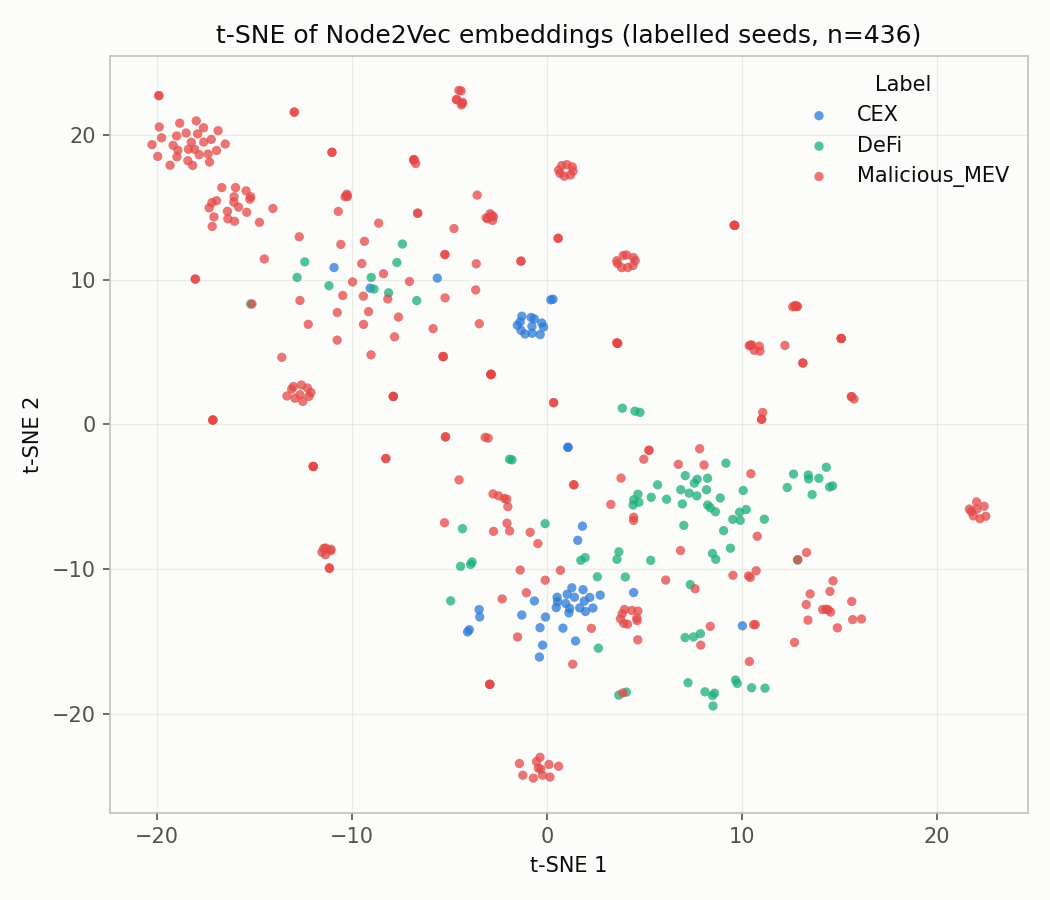

In [4]:
display(Image(filename=str(OUTPUT_DIR / "tsne_node2vec_seeds.png"), width=760))

## 4. KMeans and Louvain alignment with the three labels

KMeans partitions the 64-dimensional embeddings into three clusters. Louvain detects communities on the complete weighted graph and then assigns each labelled seed its community identifier. NMI and ARI measure agreement between clusters and public labels; ARI corrects for chance agreement. Silhouette measures cluster cohesion in the embedding space.

The permutation test holds each clustering fixed and shuffles the labels 2,000 times to estimate whether observed agreement exceeds the random-label baseline. Statistical significance and effect magnitude answer different questions. ARI values near zero indicate weak role separation even when the permutation p-value is small.

In [5]:
clustering = pd.read_csv(OUTPUT_DIR / "clustering_evaluation_summary.csv")
significance = pd.read_csv(OUTPUT_DIR / "clustering_significance_test.csv")
display(clustering)
display(significance)

,method,n_clusters,NMI,ARI,Silhouette
0,KMeans,3,0.1632,0.0265,0.1778
1,Louvain,90,0.2185,0.0131,0.3101


,method,nmi_observed,nmi_null_mean,nmi_null_std,nmi_p_value,ari_observed,ari_null_mean,ari_null_std,ari_p_value
0,KMeans,0.1632,0.0053,0.0038,0.0,0.0265,-0.0003,0.0115,0.0195
1,Louvain,0.2185,0.0905,0.0072,0.0,0.0131,-0.0001,0.0056,0.0155


## 5. Cluster-selection checks with the k scan and DBSCAN

The scan across `k=2...8` measures sensitivity to the selected number of KMeans clusters. DBSCAN provides a density-based check using several `eps` values. Weak or unstable label agreement across these alternatives supports the conclusion that the embedding space contains limited natural separation for the three address roles.

,k,silhouette,NMI,ARI
0,2,0.1709,0.1822,0.1716
1,3,0.1778,0.1632,0.0265
2,4,0.1903,0.1597,-0.0606
3,5,0.2034,0.1575,-0.0490
4,6,0.1225,0.1738,0.0385
5,7,0.1383,0.1707,-0.0070
6,8,0.1421,0.1674,0.0167


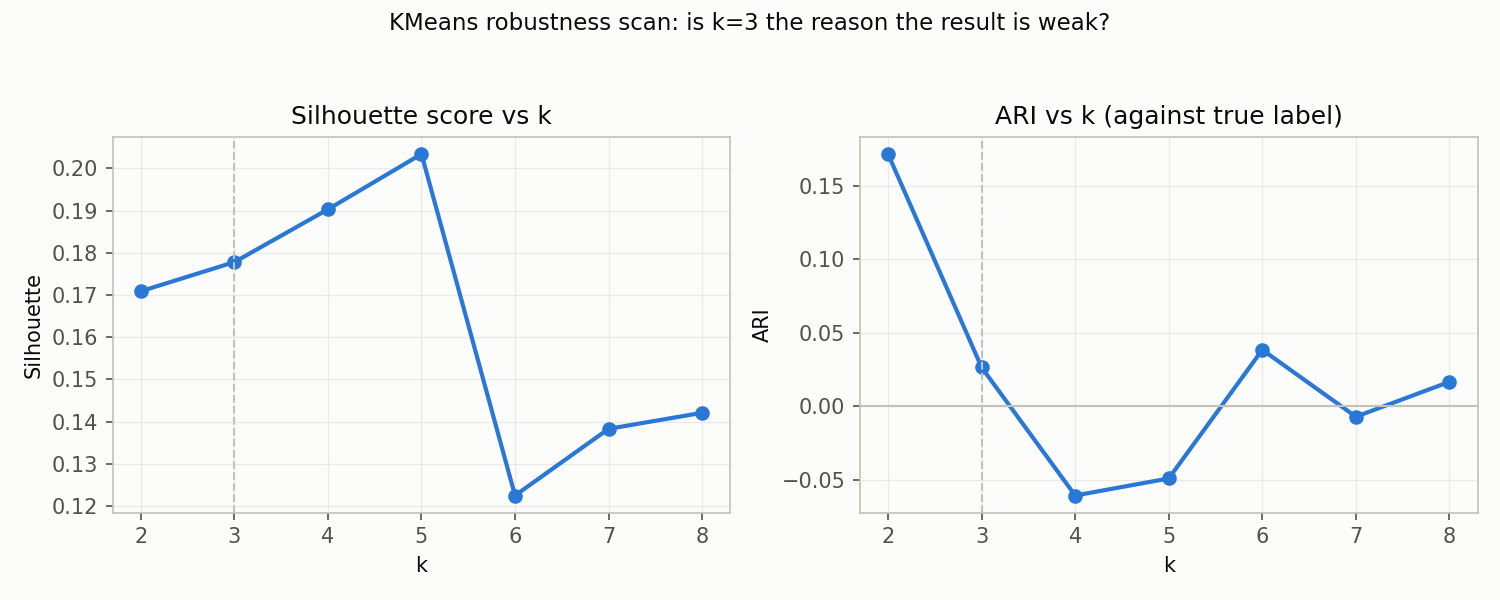

,eps,n_clusters,noise_ratio,NMI,ARI
0,2.8668,11,0.6697,0.2328,0.0234
1,5.0351,12,0.4312,0.1518,-0.0003
2,8.0213,4,0.2661,0.0549,-0.0855
3,9.3533,1,0.1147,NaN,NaN
4,10.5227,1,0.0390,NaN,NaN
5,11.3673,1,0.0206,NaN,NaN


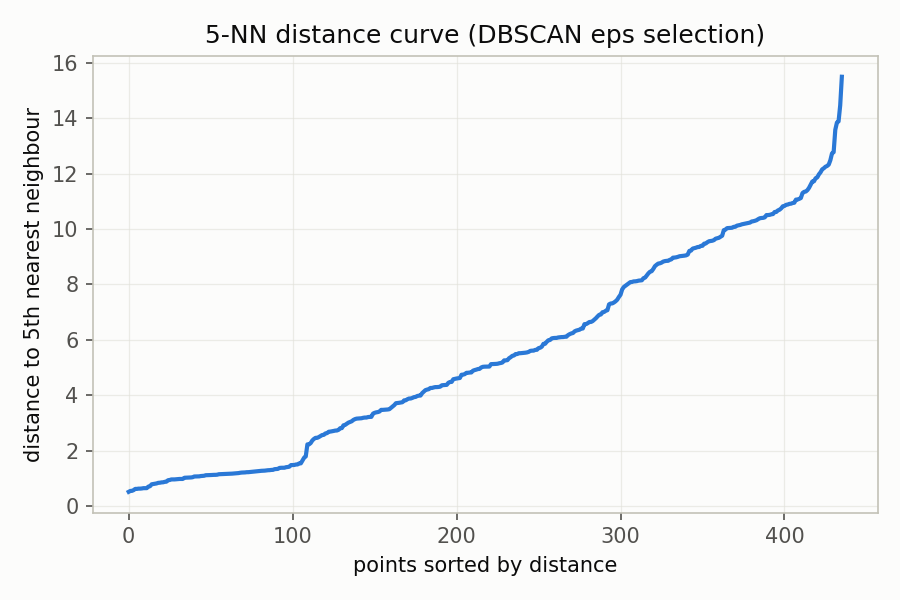

In [6]:
display(pd.read_csv(OUTPUT_DIR / "kmeans_k_scan.csv"))
display(Image(filename=str(OUTPUT_DIR / "kmeans_k_scan.png"), width=820))
display(pd.read_csv(OUTPUT_DIR / "dbscan_eps_scan.csv"))
display(Image(filename=str(OUTPUT_DIR / "dbscan_k_distance.png"), width=720))

## 6. Class-balance robustness across 50 repeated samples

The 436 embedded labelled addresses have an imbalanced class distribution: 51 CEX, 86 DeFi, and 299 MEV-related addresses. `repeated_balanced_ari.py` draws 51 addresses from each class for a balanced sample of 153 addresses and repeats the procedure 50 times. It evaluates the fixed full-sample KMeans clustering and a newly fitted KMeans model on every balanced subset. The resulting distributions estimate how strongly class imbalance influences the observed ARI.

,method,ari_mean,ari_std,ari_p5,ari_p50,ari_p95,ari_min,ari_max,pct_significant_at_0.05
0,"KMeans (fixed full-sample clustering, balanced...",0.1303,0.0338,0.0819,0.1312,0.1880,0.0804,0.2283,1.0
1,KMeans (refit fresh on each balanced subset),0.1551,0.0489,0.0824,0.1544,0.2277,0.0595,0.2839,1.0


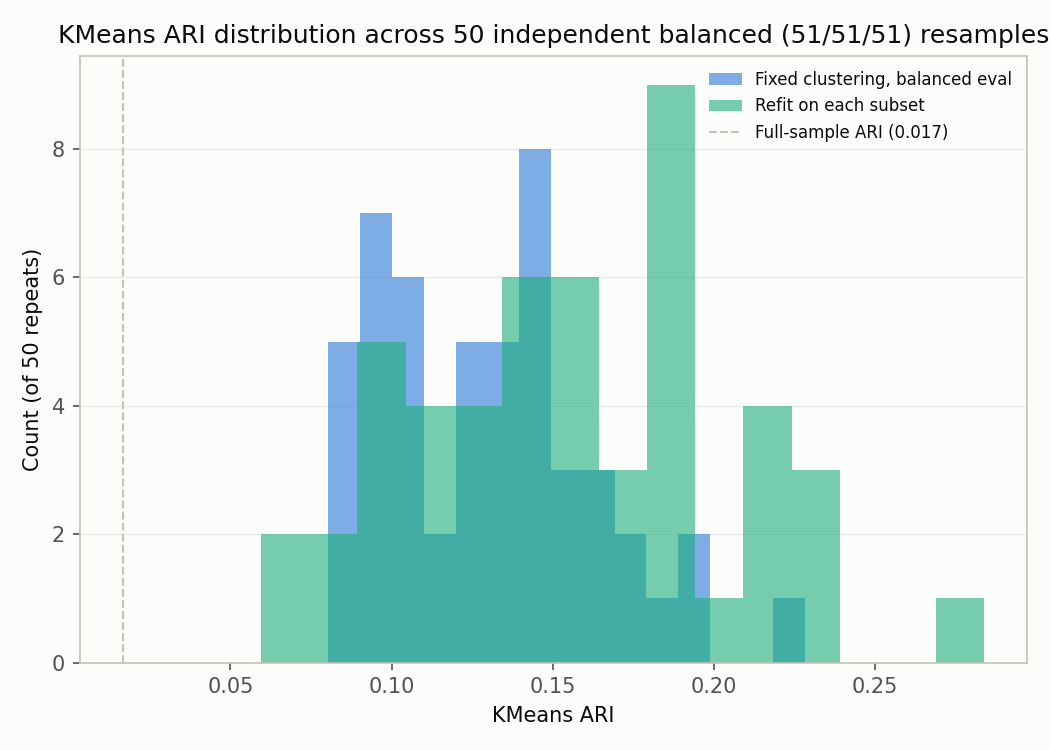

In [7]:
display(pd.read_csv(OUTPUT_DIR / "balanced_ari_summary.csv"))
display(Image(filename=str(OUTPUT_DIR / "balanced_ari_distribution.png"), width=760))

## 7. Node2Vec p/q sensitivity and multi-seed stability

Parameter `p` controls the tendency to return to the previous node, while `q` controls the balance between local exploration and outward exploration. The experiment compares the unbiased baseline `(1,1)`, a BFS-like setting `(0.25,4)`, and a DFS-like setting `(4,0.25)`. Random walks and Word2Vec initialisation introduce stochastic variation, so the final comparison aggregates results across five Node2Vec training seeds.

,setting,p,q,n_seeds,kmeans_nmi,kmeans_nmi_p,kmeans_ari,kmeans_ari_p,balanced_ari_mean,balanced_ari_std,balanced_ari_pct_significant
0,"baseline (unbiased, DeepWalk-equivalent)",1.00,1.00,436,0.1672,0.0,0.0412,0.0005,0.1348,0.0350,1.0
1,BFS-like (local/structural),0.25,4.00,436,0.1463,0.0,0.0487,0.0000,0.1214,0.0331,1.0
2,DFS-like (outward/community),4.00,0.25,436,0.1458,0.0,-0.0308,0.9940,0.1029,0.0320,1.0


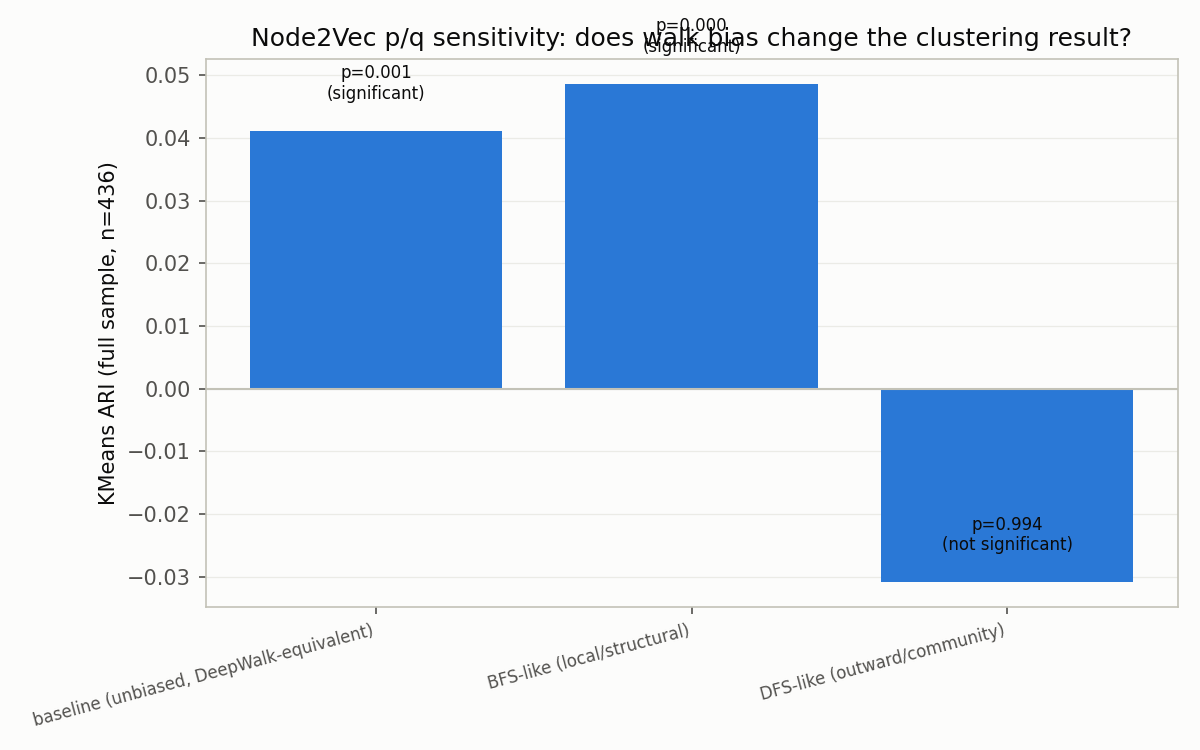

,setting,p,q,n_train_seeds,ari_mean_across_seeds,ari_std_across_seeds,ari_min_across_seeds,ari_max_across_seeds
0,"baseline (unbiased, DeepWalk-equivalent)",1.00,1.00,5,0.1394,0.0082,0.1312,0.1531
1,BFS-like (local/structural),0.25,4.00,5,0.1117,0.0082,0.0994,0.1223
2,DFS-like (outward/community),4.00,0.25,5,0.1046,0.0074,0.0949,0.1135


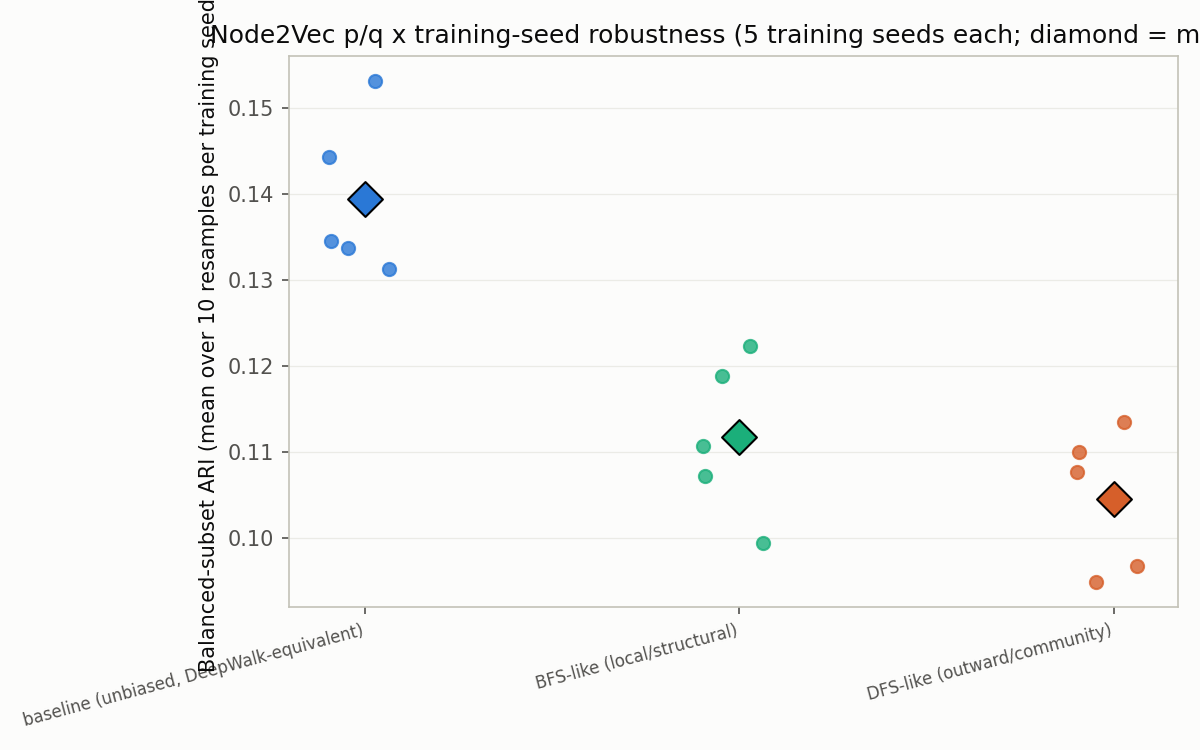

In [8]:
display(pd.read_csv(OUTPUT_DIR / "pq_sensitivity_results.csv"))
display(Image(filename=str(OUTPUT_DIR / "pq_sensitivity.png"), width=820))
display(pd.read_csv(OUTPUT_DIR / "pq_multiseed_summary.csv"))
display(Image(filename=str(OUTPUT_DIR / "pq_multiseed_distribution.png"), width=820))

## 8. Contribution to the experimental pipeline

1. **Unsupervised role alignment is weak.** Full-sample KMeans achieves an ARI of 0.0265, and Louvain achieves an ARI of 0.0131. The permutation tests place both results above the random-label baseline, while the effect sizes indicate limited natural separation among the three address roles.
2. **Class imbalance explains part of the result.** Across 50 balanced samples, the fixed KMeans evaluation has a mean ARI of approximately 0.1303, and refitting KMeans on every subset produces a mean of approximately 0.1551. These values indicate modest cluster agreement under balanced evaluation.
3. **The unbiased walk is the most stable tested setting.** Across five training seeds, `p=q=1` produces a balanced ARI of `0.1394 +/- 0.0082`, compared with `0.1117 +/- 0.0082` for the BFS-like setting and `0.1046 +/- 0.0074` for the DFS-like setting. This result supports the baseline embedding used in downstream supervised learning.
4. **RQ2 is evaluated through downstream predictive increment.** Module `04_supervised` compares hand-crafted features with hand-crafted features plus Node2Vec embeddings to measure the additional predictive information supplied by graph representation learning.

The evidence has a transductive scope defined by the fixed observed graph. Cold-start generalisation to arbitrary new addresses remains outside the evaluated design.